In [1]:
import pandas as pd
import numpy as np
import xarray as xr
import scipy
import glob
import pathlib
import matplotlib.pyplot as plt
import matplotlib as mpl
import string
letters = string.ascii_lowercase

import helpers
import plot_helpers

extra_figs = pathlib.Path(f'/work/bb1153/b382635/plots/model_paper/grl_resubmission/figures/paper_supporting_results')
extra_figs.mkdir(parents=1, exist_ok=1)

In [2]:
# load data

datadir = pathlib.Path(f'/work/bb1153/b382635/plots/model_paper/grl_resubmission/data/statistics_L2')
ds_flist = sorted(list(datadir.glob('*.nc')))
li = []
for i in range(len(ds_flist)):
    ds = xr.open_dataset(ds_flist[i])
    li.append(ds)
ds = xr.concat(li, dim='system')

In [3]:
# filter data

gsystems = ds.max_CMF.dropna('system').system
ds = ds.sel(system=gsystems)
# ds = ds.where(ds.category=='isolated').dropna('system', how='all')
ds = ds.where(ds.lifestages_valid).dropna('system', how='all')

print(ds.system.size, 'deep convective clouds')

2693 deep convective clouds


In [4]:
# add ABHs

datadir = pathlib.Path('/work/bb1153/b382635/plots/model_paper/grl_submission/data/statistics_L1_submission_to_GRL')
ds_flist = sorted(list(datadir.glob('*.nc')))
li = []
for i in range(len(ds_flist)):
    da = xr.open_dataset(ds_flist[i])[["ABH"]]
    li.append(da)
dabh = xr.concat(li, dim='system')

ds["ABH_prev"] = dabh.sel(system=[x for x in dabh.system.values if x in gsystems]).ABH


#### WHERE THE ABH FALLS

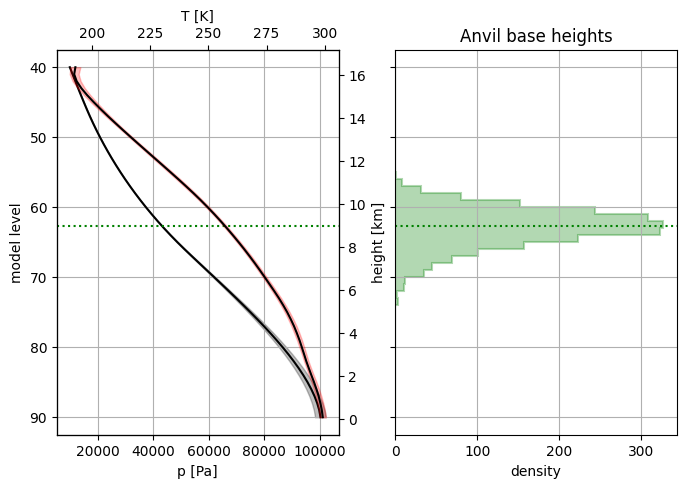

In [5]:
fig, axs = plt.subplots(1,2,figsize=(8,5),sharey=1)

ax = axs[0]
mu, std, y = ds.env_p.mean('system'), ds.env_p.std('system'), ds.level_full
ax.plot(mu, y, c='k')
ax.fill_betweenx(y, mu - std, mu + std, alpha=0.25, color='k')
ax.invert_yaxis()
ax.set(xlabel="p [Pa]", ylabel="model level")

y_zg = ds.env_zg.mean('system')
axx = ax.twinx()
axx.plot(mu, y_zg*1e-3, c='none')
axx.set(ylabel="height [km]")

ax = ax.twiny()
mu, std = ds.env_T.mean('system'), ds.env_T.std('system')
ax.plot(mu, y, c='k')
ax.fill_betweenx(y, mu - std, mu + std, alpha=0.25, color='r')
ax.set(xlabel="T [K]")

ax = axs[1]
bins = np.arange(40,90,1)
hparams = dict(orientation='horizontal', alpha=.3, histtype="stepfilled", lw=1.5)

for l,c in zip(["ABH_prev"], ["g",]):
# for l,c in zip(["ABH_prev", "ABH", "ABH_xup", "ABH_xdown"], ["g", "k", "lightgrey", "darkgrey"]):
    lab = l.split("_")[-1]
    ds[l].plot.hist(ax=ax, bins=bins, ec=c, fc=c, label=lab, **hparams)
    for ax in axs:
        ax.axhline(ds[l].median(), c=c, ls=":")
    
ax.set(xlabel="density")
ax.set_title("Anvil base heights")    

for ax in axs:
    ax.grid()


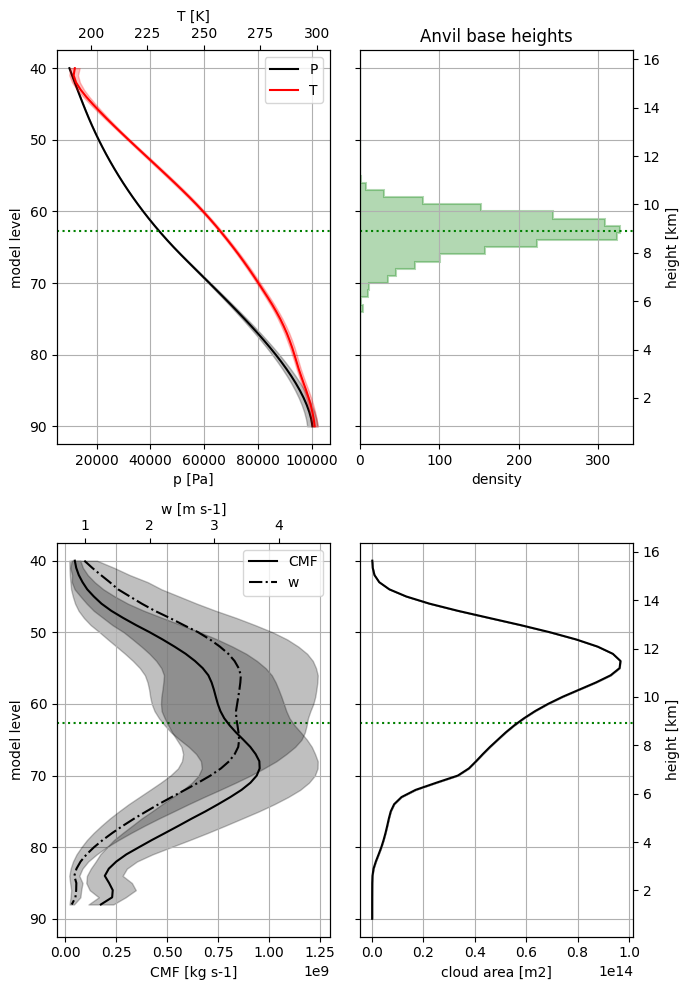

In [14]:
fig, axs = plt.subplots(2, 2, figsize=(7,10), sharey=True)
axs = axs.flat

y = ds.level_full
y_zg = ds.env_zg.mean('system')

# --- Panel 0: P and T ---
ax = axs[0]
mu, std = ds.env_p.mean('system'), ds.env_p.std('system')
ax.plot(mu, y, c='k', label="P")
ax.fill_betweenx(y, mu - std, mu + std, alpha=0.25, color='k')
ax.invert_yaxis()
ax.set(xlabel="p [Pa]", ylabel="model level")
ax.grid()

axt = ax.twiny()
mu, std = ds.env_T.mean('system'), ds.env_T.std('system')
axt.plot(mu, y, c='r', label="T")
axt.fill_betweenx(y, mu - std, mu + std, alpha=0.25, color='r')
axt.set(xlabel="T [K]")

handles, labels = ax.get_legend_handles_labels()
handles_t, labels_t = axt.get_legend_handles_labels()
ax.legend(handles + handles_t, labels + labels_t)

# --- Panel 1: Histogram of anvil base heights ---
ax1 = axs[1]
bins = np.arange(40, 90, 1)
hparams = dict(orientation='horizontal', alpha=.3, histtype="stepfilled", lw=1.5)

for l, c in zip(["ABH_prev"], ["g"]):
    lab = l.split("_")[-1]
    ds[l].plot.hist(ax=ax1, bins=bins, ec=c, fc=c, label=lab, **hparams)
    for a in axs:
        a.axhline(ds[l].median(), c=c, ls=":")

ax1.set(xlabel="density")
ax1.set_title("Anvil base heights")
ax1.grid()

axx = ax1.twinx()
axx.set_ylim(y_zg.values[[0, -1]][::-1] * 1e-3)
axx.set(ylabel="height [km]")

# --- Panel 2: CMF and w ---
ax = axs[2]
mu, std = ds.mean_CMT_z.mean('system'), ds.mean_CMT_z.std('system')
ax.plot(mu, y, c='k', label='CMF')
ax.fill_betweenx(y, mu - std, mu + std, alpha=0.25, color='k')
ax.set(xlabel="CMF [kg s-1]", ylabel="model level")
ax.grid()

axt = ax.twiny()
mu, std = ds.mean_w_z.mean('system'), ds.mean_w_z.std('system')
axt.plot(mu, y, c='k', ls='-.', label='w')
axt.fill_betweenx(y, mu - std, mu + std, alpha=0.25, color='k')
axt.set(xlabel="w [m s-1]")

handles, labels = ax.get_legend_handles_labels()
handles_t, labels_t = axt.get_legend_handles_labels()
ax.legend(handles + handles_t, labels + labels_t)

# --- Panel 3: FWC ---
ax = axs[3]
# mu, std = ds.cloud_fw.sum('system'), ds.cloud_fw.std('system')
mu, std = ds.cloud_area_z.sum('system'), ds.cloud_area_z.std('system')
ax.plot(mu, y, c='k', label='FWC')
ax.fill_betweenx(y, mu - std, mu + std, alpha=0.25, color='k')
ax.set(xlabel="cloud area [m2]")
ax.grid()

axx = ax.twinx()
axx.set_ylim(y_zg.values[[0, -1]][::-1] * 1e-3)
axx.set(ylabel="height [km]")

plt.tight_layout()

In [6]:
ds

<xarray.Dataset> Size: 200MB
Dimensions:                 (system: 2693, level_full: 51, threshold: 13,
                             interp_time: 41, phase: 5)
Coordinates:
  * system                  (system) float64 22kB 1.411e+04 ... 1.91e+03
  * level_full              (level_full) int32 204B 40 41 42 43 ... 87 88 89 90
  * threshold               (threshold) float64 104B 0.01 0.025 ... 7.5 10.0
  * interp_time             (interp_time) float64 328B 0.0 0.025 ... 0.975 1.0
  * phase                   (phase) <U10 200B 'developing' ... 'overall'
    lat                     (system) float64 22kB 10.6 7.7 -7.2 ... 14.0 2.2 5.0
    lon                     (system) float64 22kB 152.1 -69.5 ... -61.7 -58.9
Data variables: (12/74)
    ABH                     (system) float64 22kB 61.19 61.54 ... 69.83 67.02
    lifetime                (system) float64 22kB 5.25 2.25 5.25 ... 2.25 1.25
    ncores                  (system) float64 22kB 3.0 1.0 1.0 ... 1.0 1.0 1.0
    ocean_fraction          (system) float32 11kB 1.0 0.0 1.0 ... 1.0 0.0 0.0
    TOI                     (system) datetime64[ns] 22kB 2021-07-03T06:23:13 ...
    conv_lifetime           (system) float64 22kB 4.5 2.25 1.75 ... 1.25 0.75
    ...                      ...
    Apred_v2                (phase, system, interp_time) float64 4MB 8.47e+08...
    Apred_v2_cont           (phase, system, interp_time) float64 4MB 8.47e+08...
    t_max_depth             (system) float64 22kB 0.5 0.75 0.3 ... 0.5 0.75
    t_max_area              (system) float64 22kB 0.9 1.0 0.6 ... 1.0 1.0 1.0
    lifestages_valid        (system) float64 22kB 1.0 1.0 1.0 ... 1.0 1.0 1.0
    ABH_prev                (system) float64 22kB nan 64.0 67.24 ... 69.44 65.4

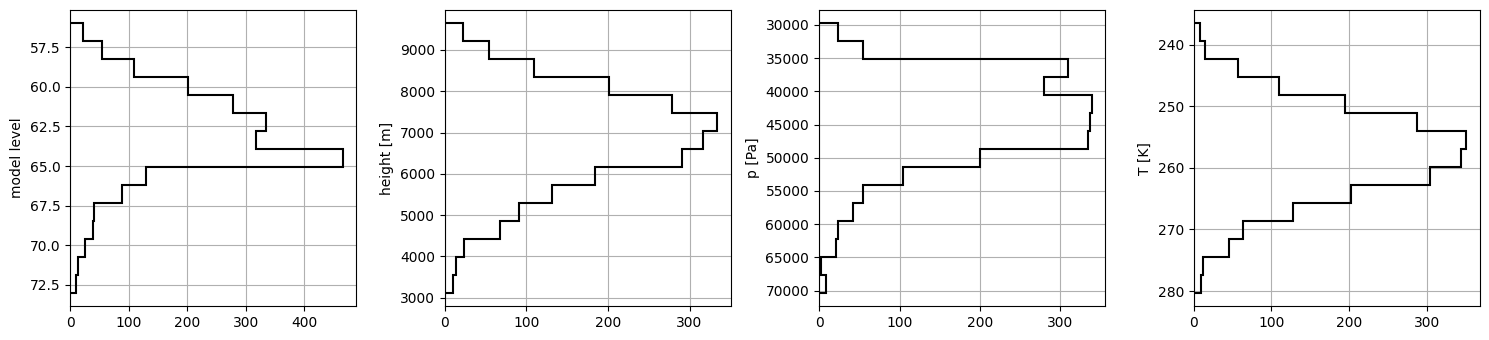

In [24]:
fig, axs = plt.subplots(1, 4, figsize=(15, 3.5), layout='tight')

l = "ABH_prev"
valid = ds.ABH_prev.isnull()

for i, x in enumerate([ds.level_full.where(ds.system), ds.env_zg, ds.env_p, ds.env_T]):
    ax = axs[i]
    lev = ds[l].isel(system=~valid)
    xi = x.isel(system=~valid).sel(level_full=lev, method='nearest').values
    ax.hist(xi, bins=15, histtype='step', fc='grey', ec='k', lw=1.5, orientation='horizontal')
    ax.grid()

axs[0].set(ylabel="model level")
axs[1].set(ylabel="height [m]")
axs[2].set(ylabel="p [Pa]")
axs[3].set(ylabel="T [K]")

for ax in (axs[0], axs[2], axs[3]):
    ax.invert_yaxis()

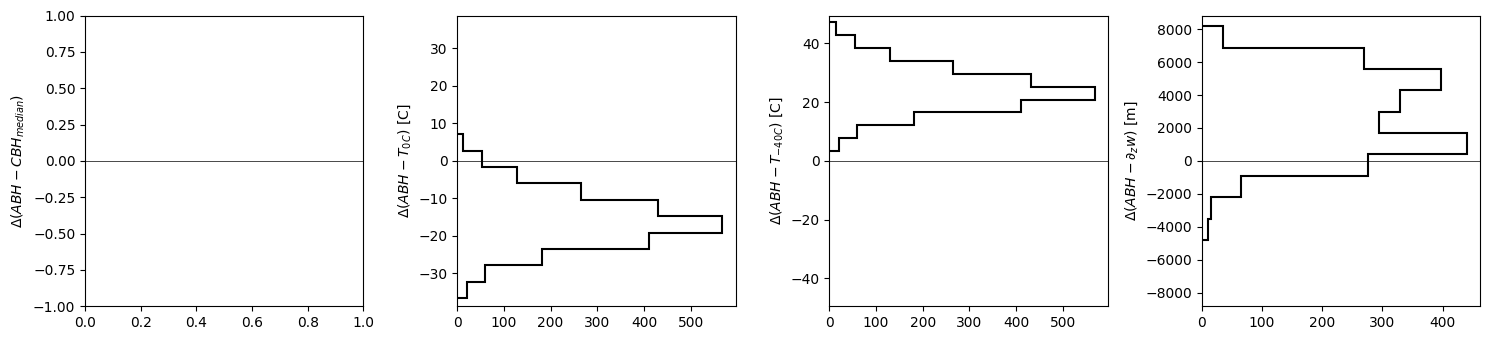

In [108]:
fig, axs = plt.subplots(1, 4, figsize=(15, 3.5), layout='tight')

l = "ABH_prev"
valid = ds.ABH_prev.isnull()
lev = ds[l].isel(system=~valid)
hparams = dict(histtype='step', fc='grey', ec='k', lw=1.5, orientation='horizontal')

ax = axs[0]
ax.set(ylabel="$\Delta(ABH - CBH_{median})$")


ax = axs[1]
xi = ds.env_T.isel(system=~valid).sel(level_full=lev, method='nearest').values
d = xi - 273.15
ax.hist(d, **hparams)
ax.set(ylabel="$\Delta(ABH - T_{0C})$ [C]")

ax = axs[2]
xi = ds.env_T.isel(system=~valid).sel(level_full=lev, method='nearest').values
d = xi - (273.15 - 40)
ax.hist(d, **hparams)
ax.set(ylabel="$\Delta(ABH - T_{-40C})$ [C]")

ax = axs[3]
# w starts decreasing
xi = ds.mean_w_z.isel(system=~valid)
xi = xi.sel(level_full = xi.level_full[::-1])
dz = xi.diff('level_full')
decreasing = (dz>0).where(~dz.isnull()).idxmin('level_full')
zg_x = ds.env_zg.isel(system=~valid).sel(level_full=decreasing)
zg_lev = ds.env_zg.isel(system=~valid).sel(level_full=lev, method='nearest')
d = zg_lev - zg_x
ax.hist(d, **hparams)
ax.set(ylabel="$\Delta(ABH - \partial_zw)$ [m]")

for ax in axs:
    ax.axhline(0, lw=.5, c='k')
    ylim = ax.get_ylim()
    max_abs = max(abs(ylim[0]), abs(ylim[1]))
    ax.set_ylim(-max_abs, max_abs)


#### SENSITVITY TO ANVIL BASE HEIGHT
A key decision is at which height to set the anvil base, here we test how this impacts results

In [5]:
d = ds[['ABH','total_CMT']]
d['frac'] = (ds.total_thick_area / ds.total_anvil_area).sel(threshold=0.25)
groups = d.groupby_bins(d.ABH, bins=d.ABH.quantile(np.arange(0,1.1,.1)).values)
for g in groups:
    pass

groups

DatasetGroupBy, grouped over 'ABH_bins'
10 groups with labels (54.198,, 57.896], ..., (66.57....

In [6]:
ds

<xarray.Dataset> Size: 88MB
Dimensions:                 (system: 1232, threshold: 13, phase: 5,
                             interp_time: 41)
Coordinates:
  * system                  (system) float64 10kB 1.411e+04 ... 1.91e+03
    lat                     (system) float64 10kB 10.6 7.7 -7.2 ... 14.0 2.2 5.0
    lon                     (system) float64 10kB 152.1 -69.5 ... -61.7 -58.9
    level_full              (system) int32 5kB 61 62 66 63 59 ... 60 63 57 70 67
  * threshold               (threshold) float64 104B 0.01 0.025 ... 7.5 10.0
  * interp_time             (interp_time) float64 328B 0.0 0.025 ... 0.975 1.0
  * phase                   (phase) <U10 200B 'developing' ... 'overall'
Data variables: (12/64)
    ABH                     (system) float64 10kB 61.19 61.54 ... 69.83 67.02
    lifetime                (system) float64 10kB 5.25 2.25 5.25 ... 2.25 1.25
    ncores                  (system) float64 10kB 3.0 1.0 1.0 ... 1.0 1.0 1.0
    ocean_fraction          (system) float32 5kB 1.0 0.0 1.0 0.0 ... 1.0 0.0 0.0
    TOI                     (system) datetime64[ns] 10kB 2021-07-03T06:23:13 ...
    conv_lifetime           (system) float64 10kB 4.5 2.25 1.75 ... 1.25 0.75
    ...                      ...
    Apred_v1_cont           (phase, system, interp_time) float64 2MB 8.47e+08...
    Apred_v2                (phase, system, interp_time) float64 2MB 8.47e+08...
    Apred_v2_cont           (phase, system, interp_time) float64 2MB 8.47e+08...
    t_max_depth             (system) float64 10kB 0.5 0.75 0.3 ... 0.5 0.75
    t_max_area              (system) float64 10kB 0.9 1.0 0.6 ... 1.0 1.0 1.0
    lifestages_valid        (system) float64 10kB 1.0 1.0 1.0 ... 1.0 1.0 1.0

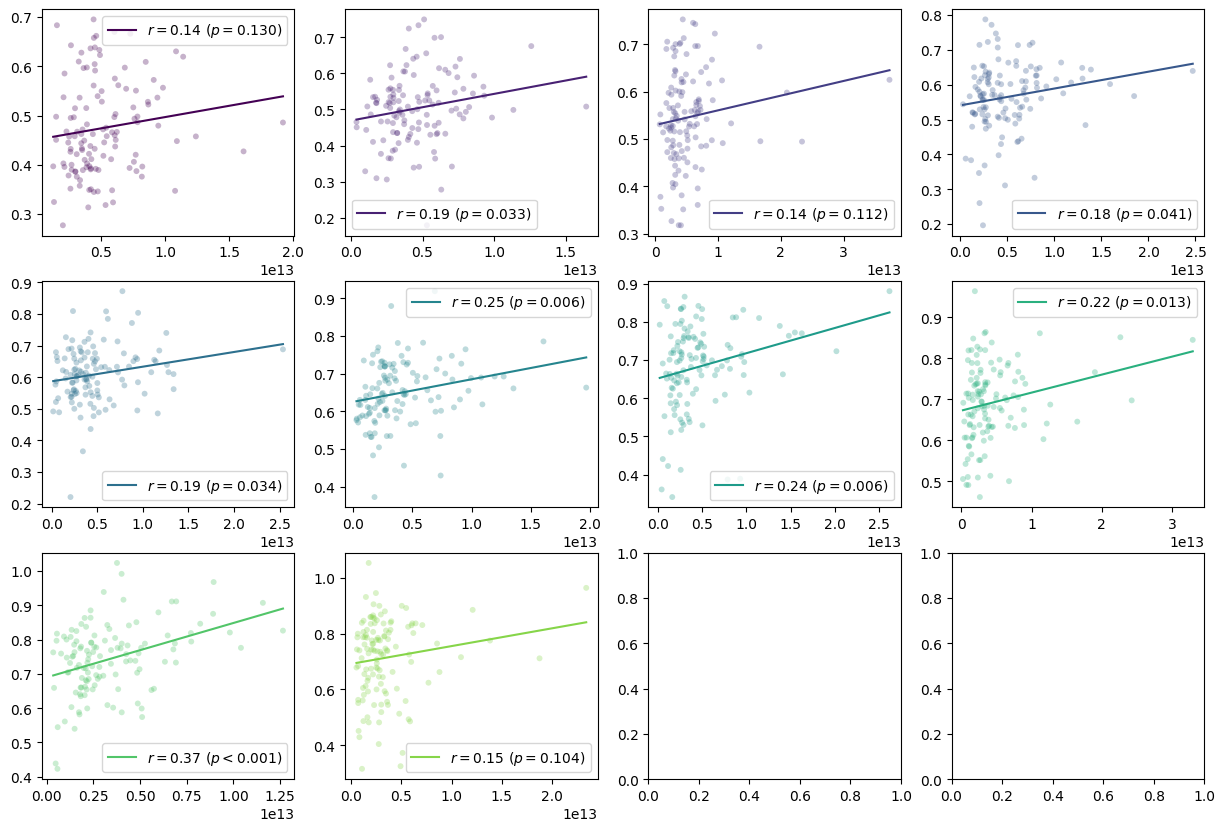

In [7]:
fig, axs = plt.subplots(3,4,figsize=(15,10))
axs = axs.flat
cmap = plt.get_cmap('viridis')

for i,g in enumerate(groups):
    c = cmap(i/11)
    ax = axs[i]
    _x, _y = g[1].total_CMT, g[1].frac
    _, _, xline, yline, result = helpers.evaluate_predictions(_x, _y)
    p_text = r"$p < 0.001$" if result.pvalue < 0.001 else rf"$p = {result.pvalue:.3f}$"
    label = rf"$r = {result.rvalue:.2f}$ ({p_text})"
    ax.scatter(_x, _y, s=18, alpha=0.3, edgecolors="none", fc=c)
    ax.plot(xline, yline, linewidth=1.5, c=c, label=label)
    ax.legend()

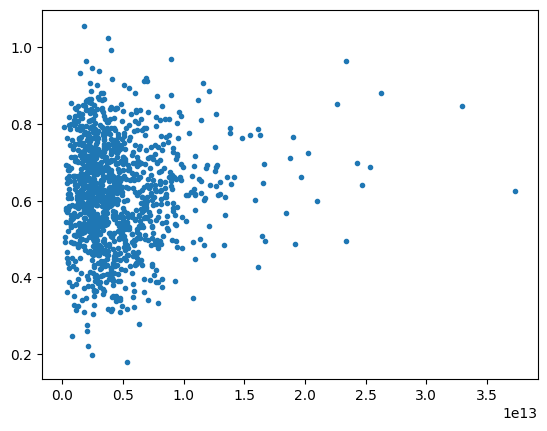

In [8]:
# x = ds.ABH
y = (ds.total_thick_area / ds.total_anvil_area).sel(threshold=0.25)
x = ds.total_CMT
# y = ds.total_anvil_area
# y = ds.total_thick_area.sel(threshold=0.25)

plt.scatter(x,y, marker='.')


(array([  1.,   4.,  12.,  30.,  52.,  81., 108., 114., 113., 111.,  96.,
         92.,  95.,  59.,  48.,  41.,  32.,  23.,  24.,  12.,  13.,   6.,
         21.,   7.,  15.,  11.,   4.,   3.,   2.,   2.]),
 array([54.19822485, 54.88912979, 55.58003474, 56.27093968, 56.96184462,
        57.65274957, 58.34365451, 59.03455945, 59.72546439, 60.41636934,
        61.10727428, 61.79817922, 62.48908416, 63.17998911, 63.87089405,
        64.56179899, 65.25270394, 65.94360888, 66.63451382, 67.32541876,
        68.01632371, 68.70722865, 69.39813359, 70.08903854, 70.77994348,
        71.47084842, 72.16175336, 72.85265831, 73.54356325, 74.23446819,
        74.92537313]),
 <BarContainer object of 30 artists>)

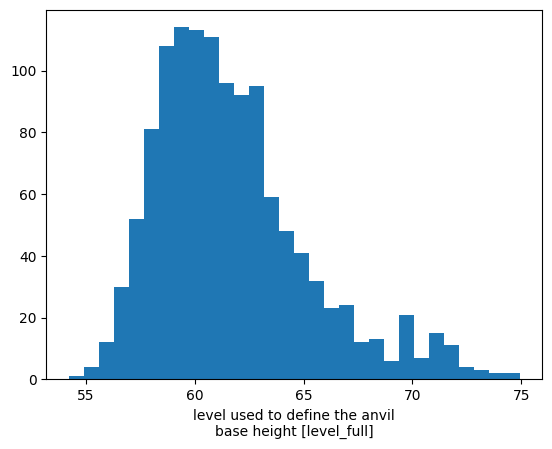

In [9]:
ds.ABH.plot.hist(bins=30)

#### INDEPENDENT ASSESSMENT: SENSITIVITY OF DOWNSTREAM RESULTS TO THE ABH DEFINITION

The anvil base height (ABH) is a single, somewhat arbitrary choice that several key
metrics are built on top of (`total_CMT`, `core_area_ABH`, etc). Here we test how
robust the paper's headline results are to that choice, using the two alternative
ABH definitions already tracked per-DCC (`xdown`, `xup` - i.e. a lower/higher anvil
base height than the nominal one), plus a fixed model level (`l60`) that ignores
ABH altogether. We test:

1. How sensitive `total_CMT` is to the ABH definition, and how the fixed `l60` level compares.
2. How sensitive the total thick anvil area is to the ABH definition.
3. How sensitive the CMT-vs-thick-anvil-fraction relationship is to the ABH definition.
4. How sensitive the proportion of thick-to-total anvil area is to the ABH definition.

`total_CMT_xdown`/`total_CMT_xup`, `total_anvil_area_xdown/xup` and
`total_thick_area_xdown/xup` are computed in `new_statistics.py`'s
`VARIABLE_OPERATIONS` and are expected to already be columns of `ds`
(re-run the `statistics_L2` batch job to populate them if they're missing).


In [10]:
# frac = thick anvil area as a fraction of total anvil area, for each ABH definition
frac_nom = (ds.total_thick_area / ds.total_anvil_area).sel(threshold=0.25).rename('frac')
frac_xdown = (ds.total_thick_area_xdown / ds.total_anvil_area_xdown).sel(threshold=0.25).rename('frac')
frac_xup = (ds.total_thick_area_xup / ds.total_anvil_area_xup).sel(threshold=0.25).rename('frac')

print(ds.system.size, 'DCCs available for the ABH-sensitivity assessment')


1232 DCCs available for the ABH-sensitivity assessment


xdown ABH            r=0.920  slope=0.997  median rel. diff=+6.80%
xup ABH              r=0.956  slope=0.806  median rel. diff=-31.51%
l60 (fixed level)    r=0.953  slope=0.964  median rel. diff=-3.35%


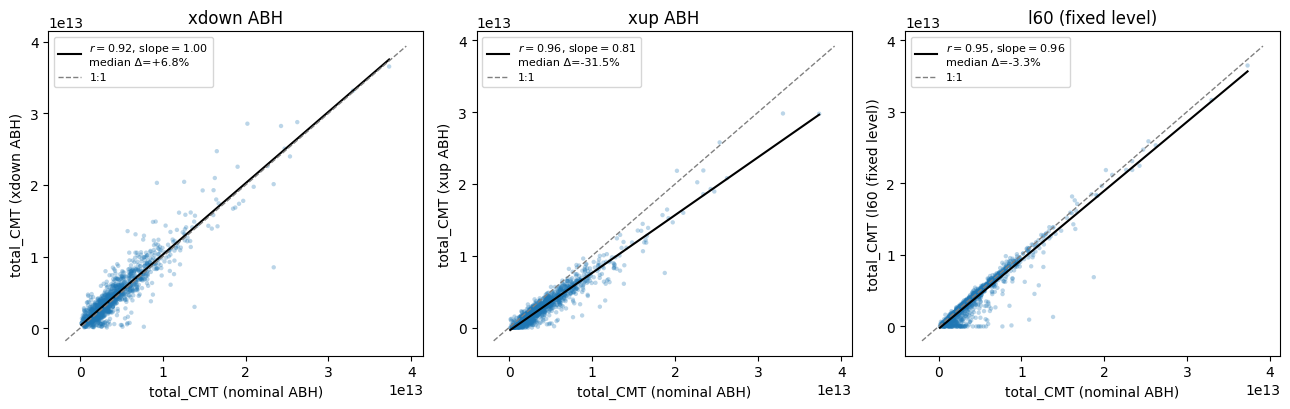

In [11]:
# 1. How sensitive is total_CMT to the ABH definition, and how does the fixed
# 'l60' level compare?

cmt_defs = {
    'xdown ABH': ds.total_CMT_xdown,
    'xup ABH': ds.total_CMT_xup,
    'l60 (fixed level)': ds.total_CMT_l60,
}

fig, axs = plt.subplots(1, 3, figsize=(13, 4.2))
for ax, (name, da) in zip(axs, cmt_defs.items()):
    _, _, xline, yline, result = helpers.evaluate_predictions(ds.total_CMT, da)
    reldiff = float(((da - ds.total_CMT) / ds.total_CMT).median())
    label = rf"$r={result.rvalue:.2f}$, slope$={result.slope:.2f}$" + "\n" + f"median Δ={reldiff:+.1%}"
    ax.scatter(ds.total_CMT, da, s=10, alpha=0.3, edgecolors='none')
    ax.plot(xline, yline, c='k', lw=1.5, label=label)
    lims = [min(ax.get_xlim()[0], ax.get_ylim()[0]), max(ax.get_xlim()[1], ax.get_ylim()[1])]
    ax.plot(lims, lims, ls='--', c='grey', lw=1, label='1:1')
    ax.set_xlabel('total_CMT (nominal ABH)')
    ax.set_ylabel(f'total_CMT ({name})')
    ax.set_title(name)
    ax.legend(fontsize=8)
    print(f"{name:20s} r={result.rvalue:.3f}  slope={result.slope:.3f}  median rel. diff={reldiff:+.2%}")
plt.tight_layout()
plt.savefig(extra_figs / f'abh_sensitivity_total_CMT.{ext}', dpi=dpi)
plt.show()


xdown ABH            r=0.991  slope=1.139  median rel. diff=+15.22%
xup ABH              r=0.935  slope=0.575  median rel. diff=-49.53%


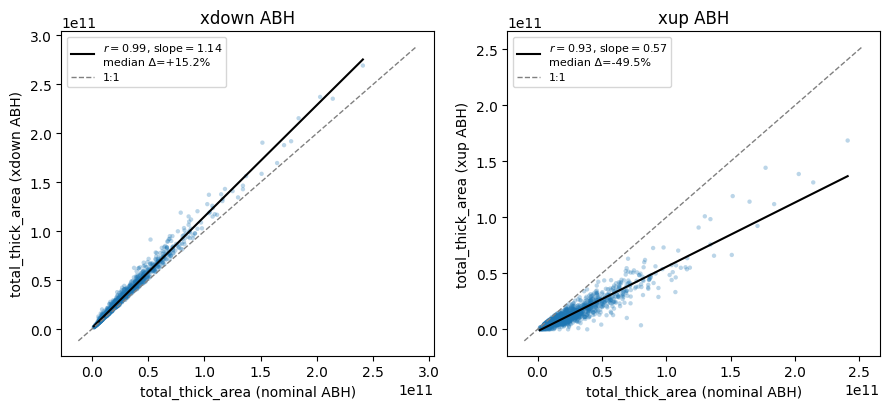

In [12]:
# 2. How sensitive is the total thick anvil area to the ABH definition?

thick_defs = {'xdown ABH': ds.total_thick_area_xdown, 'xup ABH': ds.total_thick_area_xup}

fig, axs = plt.subplots(1, 2, figsize=(9, 4.2))
for ax, (name, da) in zip(axs, thick_defs.items()):
    da = da.sel(threshold=0.25)
    nom = ds.total_thick_area.sel(threshold=0.25)
    _, _, xline, yline, result = helpers.evaluate_predictions(nom, da)
    reldiff = float(((da - nom) / nom).median())
    label = rf"$r={result.rvalue:.2f}$, slope$={result.slope:.2f}$" + "\n" + f"median Δ={reldiff:+.1%}"
    ax.scatter(nom, da, s=10, alpha=0.3, edgecolors='none')
    ax.plot(xline, yline, c='k', lw=1.5, label=label)
    lims = [min(ax.get_xlim()[0], ax.get_ylim()[0]), max(ax.get_xlim()[1], ax.get_ylim()[1])]
    ax.plot(lims, lims, ls='--', c='grey', lw=1, label='1:1')
    ax.set_xlabel('total_thick_area (nominal ABH)')
    ax.set_ylabel(f'total_thick_area ({name})')
    ax.set_title(name)
    ax.legend(fontsize=8)
    print(f"{name:20s} r={result.rvalue:.3f}  slope={result.slope:.3f}  median rel. diff={reldiff:+.2%}")
plt.tight_layout()
plt.savefig(extra_figs / f'abh_sensitivity_total_thick_area.{ext}', dpi=dpi)
plt.show()


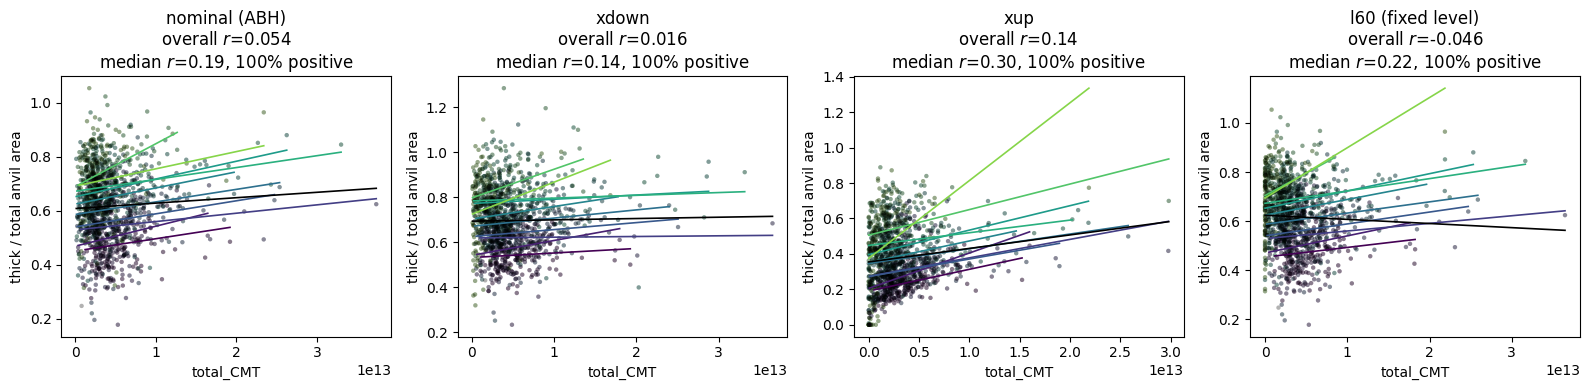

nominal (ABH)        r range [0.14, 0.37]  median r=0.19  frac positive=1.00
xdown                r range [0.01, 0.34]  median r=0.14  frac positive=1.00
xup                  r range [0.17, 0.42]  median r=0.30  frac positive=1.00
l60 (fixed level)    r range [0.12, 0.33]  median r=0.22  frac positive=1.00


In [17]:
# 3. How sensitive is the relationship between CMT and thick anvil area (as a
# fraction of total anvil area) to the ABH definition? As in the main analysis
# above, we bin DCCs by their own ABH decile before regressing, since the raw
# (unbinned) CMT-vs-fraction relationship is confounded by ABH itself.

abh_relationship_defs = {
    'nominal (ABH)': (ds.ABH, ds.total_CMT, frac_nom),
    'xdown': (ds.ABH_xdown, ds.total_CMT_xdown, frac_xdown),
    'xup': (ds.ABH_xup, ds.total_CMT_xup, frac_xup),
    'l60 (fixed level)': (ds.ABH, ds.total_CMT_l60, frac_nom),
}

fig, axs = plt.subplots(1, 4, figsize=(16, 4))
cmap = plt.get_cmap('viridis')
bin_rvalues = {}
for ax, (name, (abh_var, x, y)) in zip(axs, abh_relationship_defs.items()):
    d = xr.Dataset({'x': x, 'y': y, 'abh_var': abh_var})
    groups = d.groupby_bins(d.abh_var, bins=abh_var.quantile(np.arange(0, 1.1, .1)).values)
    rs = []
    for i, (_, g) in enumerate(groups):
        if g.system.size < 5:
            continue
        _, _, xline, yline, result = helpers.evaluate_predictions(g.x, g.y)
        rs.append(result.rvalue)
        ax.scatter(g.x, g.y, s=10, alpha=0.3, edgecolors='none', color=cmap(i / 11))
        ax.plot(xline, yline, c=cmap(i / 11), lw=1.2)
    rs = np.array(rs)
    bin_rvalues[name] = rs
    #
    _, _, xline, yline, result = helpers.evaluate_predictions(x, y)
    ax.scatter(x, y, s=10, alpha=0.3, edgecolors='none', color='k')
    ax.plot(xline, yline, c='k', lw=1.2)
    #
    ax.set_title(f"{name}\noverall $r$={result.rvalue:.2}\nmedian $r$={np.median(rs):.2f}, {np.mean(rs > 0):.0%} positive")
    ax.set_xlabel('total_CMT')
    ax.set_ylabel('thick / total anvil area')
plt.tight_layout()
plt.savefig(extra_figs / f'abh_sensitivity_CMT_vs_thick_fraction.{ext}', dpi=dpi)
plt.show()

for name, rs in bin_rvalues.items():
    print(f"{name:20s} r range [{rs.min():.2f}, {rs.max():.2f}]  median r={np.median(rs):.2f}  frac positive={np.mean(rs>0):.2f}")


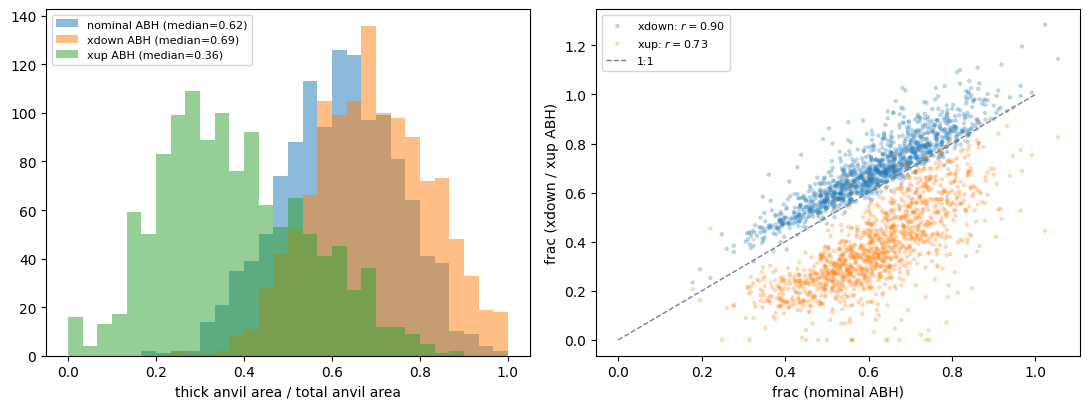

median frac: nominal=0.620  xdown=0.690  xup=0.355


In [14]:
# 4. How sensitive is the proportion of thick-to-total anvil area to the ABH definition?

fig, axs = plt.subplots(1, 2, figsize=(11, 4.2))

bins = np.linspace(0, 1, 31)
axs[0].hist(frac_nom, bins=bins, alpha=0.5, label=f'nominal ABH (median={float(frac_nom.median()):.2f})')
axs[0].hist(frac_xdown, bins=bins, alpha=0.5, label=f'xdown ABH (median={float(frac_xdown.median()):.2f})')
axs[0].hist(frac_xup, bins=bins, alpha=0.5, label=f'xup ABH (median={float(frac_xup.median()):.2f})')
axs[0].set_xlabel('thick anvil area / total anvil area')
axs[0].legend(fontsize=8)

for name, da in [('xdown', frac_xdown), ('xup', frac_xup)]:
    _, _, xline, yline, result = helpers.evaluate_predictions(frac_nom, da)
    axs[1].scatter(frac_nom, da, s=10, alpha=0.3, edgecolors='none', label=rf"{name}: $r={result.rvalue:.2f}$")
axs[1].plot([0, 1], [0, 1], ls='--', c='grey', lw=1, label='1:1')
axs[1].set_xlabel('frac (nominal ABH)')
axs[1].set_ylabel('frac (xdown / xup ABH)')
axs[1].legend(fontsize=8)
plt.tight_layout()
plt.savefig(extra_figs / f'abh_sensitivity_thick_fraction.{ext}', dpi=dpi)
plt.show()

print('median frac: nominal=%.3f  xdown=%.3f  xup=%.3f' % (float(frac_nom.median()), float(frac_xdown.median()), float(frac_xup.median())))
